# 104 · Scaling laws in miniature: how MiniVLA's validation loss depends on the number of demonstrations

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import list_episodes, load_episode
from vlacourse.minivla import MiniVLA

DATA = os.path.abspath("../data/tabletop_panda_v1")
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
STEPS, BS = 600, 16

def frames(eps):
    return [(e["front"][t], e["instruction"], e["action"][t]) for e in eps for t in range(len(e["action"]))]

@torch.no_grad()
def val_metrics(vla, data):
    vla.model.eval(); L, A = [], []
    for i in range(0, len(data), 32):
        b = data[i:i + 32]
        loss, acc = vla.loss([x[0] for x in b], [x[1] for x in b], np.stack([x[2] for x in b])); L.append(loss.item()); A.append(acc.item())
    return float(np.mean(L)), float(np.mean(A))

def run(n_eps, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    train = frames(EPS[:n_eps])
    vla = MiniVLA(ALL_ACTIONS, device=device)
    params = [p for p in vla.model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, 2e-4)
    vla.model.train()
    for step in range(STEPS):
        b = [train[j] for j in rng.integers(0, len(train), BS)]
        loss, _ = vla.loss([x[0] for x in b], [x[1] for x in b], np.stack([x[2] for x in b]))
        opt.zero_grad(); loss.backward(); opt.step()
    out = val_metrics(vla, VAL)
    del vla; torch.cuda.empty_cache()
    return out

In [2]:
EPS = [load_episode(p) for p in list_episodes(DATA)]
VAL = frames(EPS[180:])[:320]
ALL_ACTIONS = np.stack([x[2] for x in frames(EPS[:180])])
sizes, results = [10, 30, 90, 180], {}
for n in sizes:
    t0 = time.time(); results[n] = run(n)
    print(f"{n:4d} demos: val loss {results[n][0]:.3f}, val token accuracy {results[n][1]:.3f}  (same {STEPS} steps of compute, {time.time() - t0:.0f}s)")

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 19948.47it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


  10 demos: val loss 3.053, val token accuracy 0.717  (same 600 steps of compute, 67s)


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

... (4 outputs left out)

  90 demos: val loss 1.571, val token accuracy 0.754  (same 600 steps of compute, 161s)


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 17687.82it/s]

 180 demos: val loss 1.359, val token accuracy 0.759  (same 600 steps of compute, 168s)


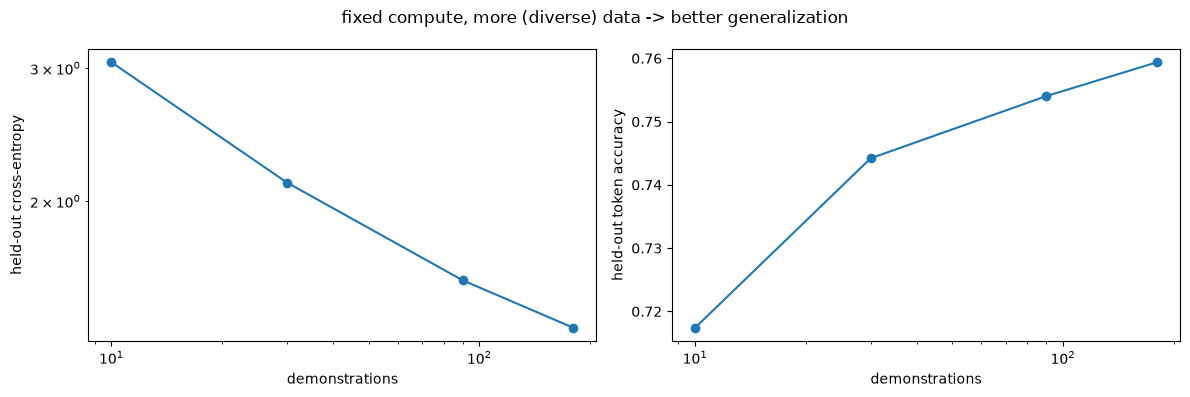

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(sizes, [results[n][0] for n in sizes], "o-"); ax[0].set_xlabel("demonstrations"); ax[0].set_ylabel("held-out cross-entropy")
ax[1].semilogx(sizes, [results[n][1] for n in sizes], "o-"); ax[1].set_xlabel("demonstrations"); ax[1].set_ylabel("held-out token accuracy")
plt.suptitle("fixed compute, more (diverse) data -> better generalization"); plt.tight_layout(); plt.show()